# Diabetes Hospital Readmission Prediction Using Supervised Machine Learning

## 1. Project Objective

The goal of this project is to build a supervised machine learning model that predicts whether a patient with diabetes will be readmitted to the hospital. Identifying high-risk patients could help hospitals decide who may benefit from extra follow-up care.

**Workflow:** Data Understanding → Data Cleaning → EDA → Feature Review → Model Training → Cross-Validation → Tuning → Final Test Evaluation → Interpretation → Conclusions

**Project structure**
- `diabetes_model.py` holds the reusable functions (load, clean, prepare, train, evaluate, tune).
- This notebook calls those functions, runs the EDA, shows the results, and explains the findings.

**Dataset:** 10,000 hospital encounters of patients with diabetes (`diabetes_clean.csv`). The target is `readmission_flag` (0 = not readmitted, 1 = readmitted).

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

import diabetes_model as dm

## 2. Data Understanding

In [18]:
df = dm.load_data("diabetes_clean.csv")
df.head()

Dataset shape: (10000, 59)


,rowID,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,...,diag_1_desc,diag_2_desc,diag_3_desc,readmission_flag,prior_utilization,utilization_group,stay_group,age_avg_los,los_difference,los_vs_age_average
0,1,Caucasian,Female,[50-60),NaN,Elective,Discharged to home,Physician Referral,1,CP,...,Spinal stenosis in cervical region,Spinal stenosis in cervical region,"Effusion of joint, site unspecified",0,0,NaN,Short,4.151568,-3.151568,At or Below Age-Group Average
1,2,Caucasian,Female,[20-30),[50-75),Urgent,Discharged to home,Physician Referral,2,UN,...,"First-degree perineal laceration, unspecified ...","Diabetes mellitus of mother, complicating preg...",Sideroblastic anemia,0,0,NaN,Short,3.216783,-1.216783,At or Below Age-Group Average
2,3,Caucasian,Male,[80-90),NaN,Not Available,Discharged/transferred to home with home healt...,NaN,7,MC,...,Pneumococcal pneumonia [Streptococcus pneumoni...,"Congestive heart failure, unspecified",Hyperosmolality and/or hypernatremia,1,1,Low,Medium,4.987318,2.012682,Above Age-Group Average
3,4,AfricanAmerican,Female,[50-60),NaN,Emergency,Discharged to home,Transfer from another health care facility,4,UN,...,Cellulitis and abscess of face,Streptococcus infection in conditions classifi...,Diabetes mellitus without mention of complicat...,0,0,NaN,Medium,4.151568,-0.151568,At or Below Age-Group Average
4,5,AfricanAmerican,Female,[50-60),NaN,Emergency,Discharged to home,Emergency Room,5,NaN,...,"Bipolar I disorder, single manic episode, unsp...",Diabetes mellitus without mention of complicat...,Depressive type psychosis,0,0,NaN,Medium,4.151568,0.848432,Above Age-Group Average


In [19]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 59 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   rowID                     10000 non-null  int64  
 1   race                      9779 non-null   str    
 2   gender                    10000 non-null  str    
 3   age                       10000 non-null  str    
 4   weight                    408 non-null    str    
 5   admission_type_id         9279 non-null   str    
 6   discharge_disposition_id  9531 non-null   str    
 7   admission_source_id       9064 non-null   str    
 8   time_in_hospital          10000 non-null  int64  
 9   payer_code                4659 non-null   str    
 10  medical_specialty         5900 non-null   str    
 11  num_lab_procedures        10000 non-null  int64  
 12  num_procedures            10000 non-null  int64  
 13  num_medications           10000 non-null  int64  
 14  number_outpatient 

In [20]:
# Target distribution: counts and percentages
target_summary = pd.DataFrame({
    "Count": df["readmission_flag"].value_counts(),
    "Percent": (df["readmission_flag"].value_counts(normalize=True) * 100).round(2),
})
target_summary.index = ["Not Readmitted", "Readmitted"]
target_summary

,Count,Percent
Not Readmitted,6035,60.35
Readmitted,3965,39.65


**Interpretation:** About 60% of encounters were not readmitted and about 40% were. The classes are moderately imbalanced, not extremely so. A model that always predicts "not readmitted" would already reach roughly 60% accuracy, so accuracy alone is a weak measure here. This is why precision, recall, F1-score, and ROC-AUC are also used, and why the train/test split is stratified.

In [21]:
# Data quality check: missing values and duplicates
missing = df.isnull().sum()
missing_summary = pd.DataFrame({
    "Missing Count": missing,
    "Missing %": (missing / len(df) * 100).round(2),
})
missing_summary = missing_summary[missing_summary["Missing Count"] > 0]
print("Duplicate rows:", df.duplicated().sum())
missing_summary.sort_values("Missing %", ascending=False)

Duplicate rows: 0


,Missing Count,Missing %
weight,9592,95.92
max_glu_serum,9336,93.36
A1Cresult,8379,83.79
utilization_group,6471,64.71
payer_code,5341,53.41
medical_specialty,4100,41.00
admission_source_id,936,9.36
admission_type_id,721,7.21
discharge_disposition_id,469,4.69
race,221,2.21


## 3. Data Cleaning

Cleaning is done by `dm.clean_data()`. Below is the reasoning for each decision.

| Removed | Reason |
|---|---|
| `weight` (95.9% missing), `max_glu_serum` (93.4%), `A1Cresult` (83.8%) | Too sparse to impute reliably. Imputing over 80% of a column would mostly invent data. |
| `rowID` | A row identifier. It has no predictive meaning. |
| `readmitted` | The original outcome column. It contains the same information as the target, so keeping it would leak the answer into the features. |
| `diag_1_desc`, `diag_2_desc`, `diag_3_desc` | Text descriptions of the diagnosis codes. The codes (`diag_1`, `diag_2`, `diag_3`) are kept. |
| `age_avg_los`, `los_difference`, `los_vs_age_average` | Engineered using averages over the full dataset, before the train/test split. Test-set information would leak into training. |

**Missing values that remain** (for example `payer_code`, `medical_specialty`, `race`) are not filled in here. They are handled inside the modeling pipeline (median for numbers, most frequent for categories) so that the fill values are learned from training data only.

**Limitation:** For `max_glu_serum` and `A1Cresult`, a missing value likely means the test was not performed, which can itself be clinically informative. Keeping these columns as a "Not measured" category is an alternative worth testing in future work.

In [22]:
df_clean = dm.clean_data(df)

Dataset shape after cleaning: (10000, 48)


## 4. Exploratory Data Analysis (EDA)

EDA looks at how patient characteristics differ between readmitted and non-readmitted encounters. These are associations only. They do not show that any factor causes readmission.

In [23]:
# Readmission rate and group size for each age group
age_summary = (
    df_clean.groupby("age")["readmission_flag"]
    .agg(rate="mean", encounters="count")
)
age_summary["rate"] = age_summary["rate"] * 100
age_summary.round(1)

,rate,encounters
age,,
[0-10),9.7,31
[10-20),25.6,82
[20-30),30.8,143
[30-40),29.3,417
[40-50),35.3,978
[50-60),37.2,1722
[60-70),40.5,2187
[70-80),43.0,2595
[80-90),44.3,1577


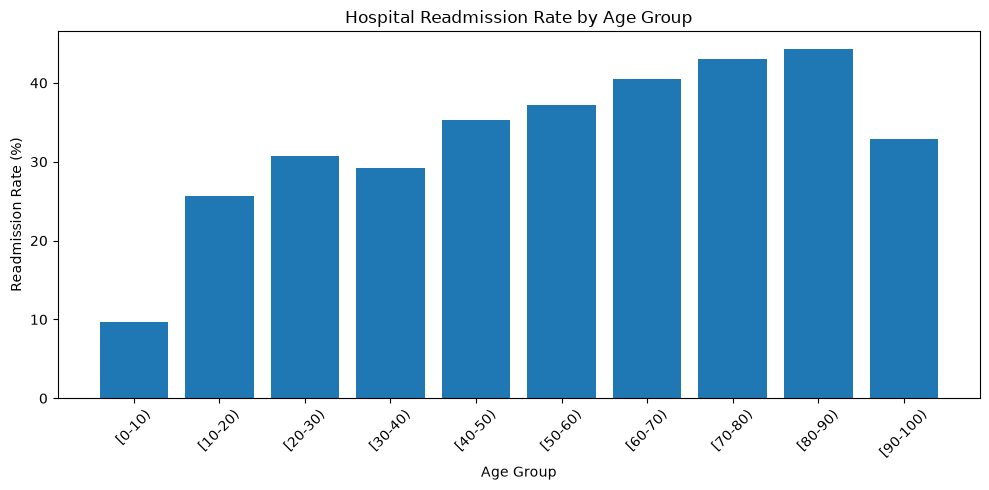

In [24]:
plt.figure(figsize=(10, 5))
plt.bar(age_summary.index, age_summary["rate"])
plt.xlabel("Age Group")
plt.ylabel("Readmission Rate (%)")
plt.title("Hospital Readmission Rate by Age Group")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Interpretation:** The readmission rate rises with age, from about 35% at ages 40-50 to about 44% at ages 80-90, then falls to about 33% in the 90-100 group. The lowest rates are in the youngest groups. Check the `encounters` column above: very small groups (such as 0-10) produce unstable percentages, so I should not read much into them. Age appears to be informative for prediction, so it stays in the model, but this chart does not explain *why* older patients are readmitted more often.

In [27]:
def mean_by_readmission(column):
    """Average of one column for each readmission group."""
    result = df_clean.groupby("readmission_flag")[column].mean()
    result.index = ["Not Readmitted", "Readmitted"]
    return result


def plot_mean_by_readmission(column, ylabel, title):
    """Bar chart comparing the group averages of one column."""
    result = mean_by_readmission(column)
    plt.figure(figsize=(6, 4))
    plt.bar(result.index, result.values)
    plt.xlabel("Readmission Status")
    plt.ylabel(ylabel)
    plt.title(title)
    plt.tight_layout()
    plt.show()
    return result.round(2)

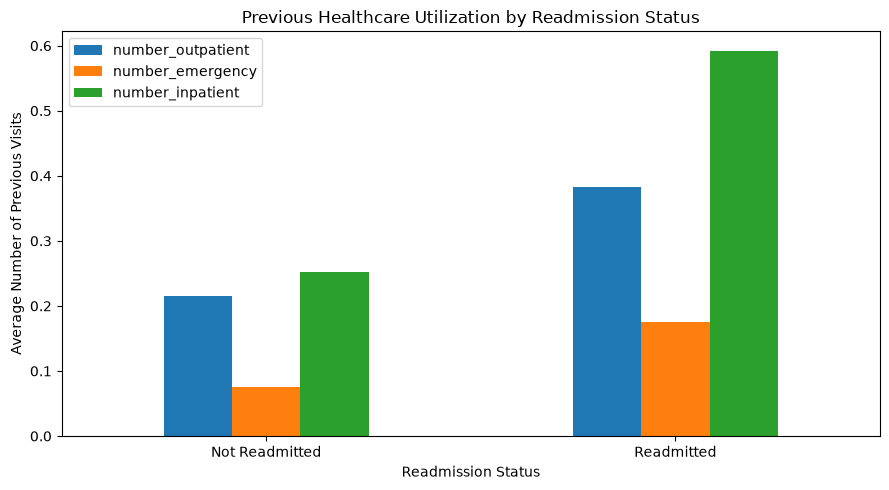

,number_outpatient,number_emergency,number_inpatient
Not Readmitted,0.215,0.075,0.253
Readmitted,0.383,0.176,0.592


In [26]:
# Previous healthcare utilization
utilization = df_clean.groupby("readmission_flag")[
    ["number_outpatient", "number_emergency", "number_inpatient"]
].mean()
utilization.index = ["Not Readmitted", "Readmitted"]

utilization.plot(kind="bar", figsize=(9, 5))
plt.xlabel("Readmission Status")
plt.ylabel("Average Number of Previous Visits")
plt.title("Previous Healthcare Utilization by Readmission Status")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
utilization.round(3)

**Interpretation:** Readmitted patients had more prior visits of every type. On average they had about 0.59 prior inpatient visits compared with 0.25 for non-readmitted patients (more than double), 0.18 versus 0.07 prior emergency visits, and 0.38 versus 0.22 prior outpatient visits. This is the clearest difference in the EDA. It suggests that a patient's recent history of hospital use is a strong signal, which is why I combined these counts into a `prior_utilization` feature. The averages are small because most patients have zero prior visits, so a few frequent users pull the averages up.

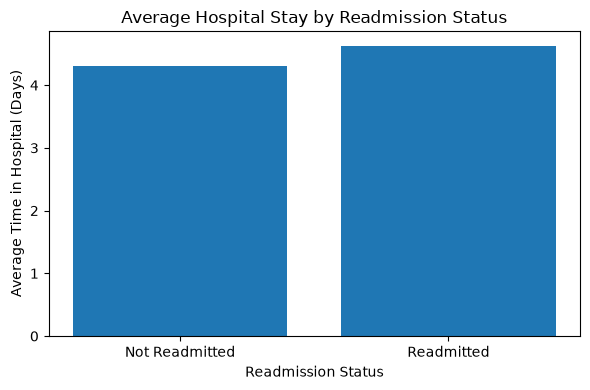

Not Readmitted    4.31
Readmitted        4.63
Name: time_in_hospital, dtype: float64

In [28]:
plot_mean_by_readmission("time_in_hospital", "Average Time in Hospital (Days)",
                         "Average Hospital Stay by Readmission Status")

**Interpretation:** Readmitted patients stayed slightly longer on average (about 4.6 days versus 4.3). The difference is small, so length of stay alone is probably a weak predictor. Group averages also hide how much the two distributions overlap.

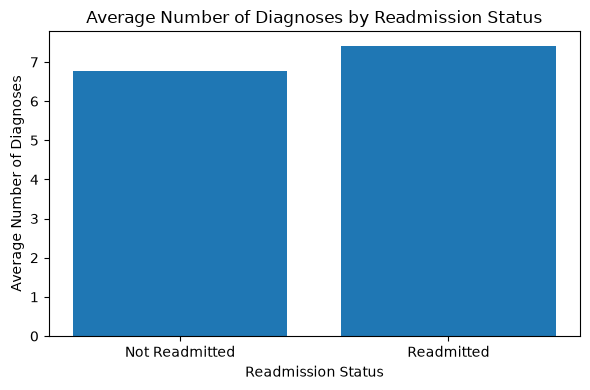

Not Readmitted    6.77
Readmitted        7.41
Name: number_diagnoses, dtype: float64

In [29]:
plot_mean_by_readmission("number_diagnoses", "Average Number of Diagnoses",
                         "Average Number of Diagnoses by Readmission Status")

**Interpretation:** Readmitted patients had more recorded diagnoses (about 7.4 versus 6.8). A higher number of diagnoses may reflect more complex health conditions, but that is an assumption. The data only shows that the two go together.

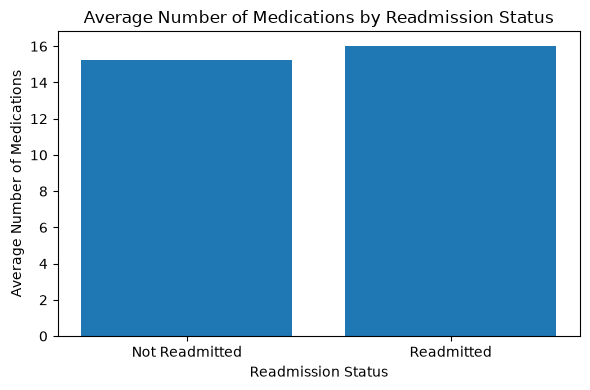

Not Readmitted    15.26
Readmitted        16.02
Name: num_medications, dtype: float64

In [30]:
plot_mean_by_readmission("num_medications", "Average Number of Medications",
                         "Average Number of Medications by Readmission Status")

**Interpretation:** Readmitted patients received slightly more medications (about 16.0 versus 15.3). As with length of stay, the gap is small.

**What the EDA means for modeling:** Prior utilization shows the clearest separation between the groups, while length of stay and medication count show only small differences. No single variable separates readmitted from non-readmitted patients cleanly, so I should expect only moderate model performance and should use models that combine many features.

## 5. Feature Review and Leakage Check

The dataset arrives with three engineered features still in place: `prior_utilization`, `utilization_group`, and `stay_group`. Before modeling I check how they were built, because features based on information from the whole dataset (such as averages or quantile cut points) can leak test information into training.

In [31]:
# Is prior_utilization simply the sum of the three prior-visit counts?
visit_sum = df_clean[["number_outpatient", "number_emergency", "number_inpatient"]].sum(axis=1)
print("prior_utilization equals the sum of visit counts in",
      round((df_clean["prior_utilization"] == visit_sum).mean() * 100, 1), "% of rows")

# How do the grouped versions relate to the underlying numbers?
for group_col, value_col in [("utilization_group", "prior_utilization"),
                             ("stay_group", "time_in_hospital")]:
    print(f"\n{group_col} (including missing):")
    print(df_clean.groupby(group_col, dropna=False)[value_col].agg(["min", "max", "count"]))

prior_utilization equals the sum of visit counts in 100.0 % of rows

utilization_group (including missing):
                   min  max  count
utilization_group                 
High                 6   49    192
Low                  1    2   2567
Medium               3    5    770
NaN                  0    0   6471

stay_group (including missing):
            min  max  count
stay_group                 
Long          8   14   1527
Medium        4    7   3691
Short         1    3   4782


**Interpretation (fill in after running):**
- If `prior_utilization` is a plain row-by-row sum, it is safe: it uses only the patient's own data.
- `utilization_group` had 64.7% missing values in the raw data. If those missing rows all have `prior_utilization = 0`, the missing values are not true gaps. They are patients with *no* prior visits who fell outside a bin edge. The pipeline currently fills them with the most frequent category, which would wrongly label them as a low or medium user. If this is the case, replace the missing values with an explicit "None" group before modeling.
- If the cut points for the groups came from quantiles of the full dataset, that is mild leakage. Fixed, clinically meaningful cut points (like 0, 1-2, 3+) are safer.

Write what you find here: ______________________

## 6. Model Preparation

`dm.prepare_data()` separates the target, splits the data 80/20 with stratification, and removes constant columns using the **training data only**. All imputing, scaling, and encoding happens inside scikit-learn pipelines, so those steps are learned from training data (and from training folds only during cross-validation).

In [32]:
X_train, X_test, y_train, y_test = dm.prepare_data(df_clean)

print("\nReadmission rate in train:", round(y_train.mean() * 100, 1), "%")
print("Readmission rate in test: ", round(y_test.mean() * 100, 1), "%")

Dropping constant columns: ['acetohexamide', 'troglitazone', 'examide', 'citoglipton', 'glimepiride.pioglitazone', 'metformin.rosiglitazone', 'metformin.pioglitazone']
X_train: (8000, 40) | X_test: (2000, 40)

Readmission rate in train: 39.6 %
Readmission rate in test:  39.6 %


## 7. Model Training and Selection

Three models are trained with the same function:
- **Logistic Regression** (baseline): simple and interpretable, a benchmark for the other models.
- **Balanced Logistic Regression**: same model, but errors on the rarer class (readmitted) are weighted more heavily.
- **Random Forest**: an ensemble of decision trees that can capture non-linear patterns and interactions.

**Why several metrics matter for readmission prediction**
- **Recall:** of the patients who were truly readmitted, the share the model caught. A *false negative* is a patient who is later readmitted but was predicted safe. They might have benefited from follow-up care and did not get flagged, so recall is especially important here.
- **Precision:** of the patients the model flagged, the share who were truly readmitted. Low precision means follow-up resources are spent on patients who did not need them (false positives).
- **F1-score:** the balance between precision and recall in one number.
- **ROC-AUC:** how well the model *ranks* patients by risk across all possible cutoffs. Unlike the other metrics, it does not depend on the 0.5 cutoff, which makes it the fairest way to compare models.

**Validation approach:** models are compared with 5-fold stratified cross-validation on the training data. The test set is not used for choosing a model. It is used once at the end.

In [33]:
model_names = {
    "Logistic Regression": "logistic",
    "Balanced Logistic Regression": "logistic_balanced",
    "Random Forest": "random_forest",
}

models = {label: dm.train_model(key, X_train, y_train) for label, key in model_names.items()}

In [34]:
# Compare models with cross-validation on the training data only
cv_table = dm.cross_validate_models(models, X_train, y_train)
cv_table

,Accuracy (mean),Accuracy (std),Precision (mean),Precision (std),Recall (mean),Recall (std),F1 Score (mean),F1 Score (std),ROC-AUC (mean),ROC-AUC (std)
Logistic Regression,0.634,0.006,0.550,0.011,0.416,0.007,0.474,0.007,0.664,0.013
Balanced Logistic Regression,0.615,0.009,0.512,0.009,0.604,0.011,0.554,0.009,0.665,0.013
Random Forest,0.653,0.008,0.617,0.018,0.329,0.018,0.429,0.017,0.681,0.014


**Interpretation (original run, check against your output):**
- Random Forest has the best cross-validated ROC-AUC (about 0.68) versus about 0.665 for both logistic regression models, so it ranks patients best.
- Balanced Logistic Regression has the same ROC-AUC as plain Logistic Regression, but much higher recall (about 0.60 versus 0.42). Class balancing did not make the model better at *ranking* patients. It moved the cutoff so that more patients get flagged as readmitted, raising recall and lowering precision. This is a trade-off, not an improvement in overall quality.
- Standard deviations across folds are small (about 0.01), so the differences between models are meaningful but modest.

## 8. Hyperparameter Tuning

`GridSearchCV` tries every combination of the settings below with 5-fold cross-validation on the training data and keeps the one with the best ROC-AUC.

| Hyperparameter | Values tried | Why |
|---|---|---|
| `n_estimators` | 100, 200 | More trees make predictions more stable but slower. |
| `max_depth` | None, 10, 20 | Limits how complex each tree can get, which controls overfitting. |
| `min_samples_split` | 2, 5 | Larger values force simpler, more general trees. |
| `class_weight` | None, "balanced" | Gives more weight to the rarer class (readmitted). |

ROC-AUC was chosen as the tuning score because it does not depend on a fixed 0.5 cutoff.

In [35]:
grid = dm.tune_model("random_forest", X_train, y_train)

print("Best parameters:", grid.best_params_)
print("Best CV ROC-AUC (tuned):  ", round(grid.best_score_, 3))
print("CV ROC-AUC (baseline RF): ", cv_table.loc["Random Forest", "ROC-AUC (mean)"])

Best parameters: {'classifier__class_weight': 'balanced', 'classifier__max_depth': 20, 'classifier__min_samples_split': 5, 'classifier__n_estimators': 200}
Best CV ROC-AUC (tuned):   0.689
CV ROC-AUC (baseline RF):  0.681


In [36]:
# Which setting mattered? Best CV ROC-AUC reached with each class_weight option
results = pd.DataFrame(grid.cv_results_)
results["class_weight"] = results["param_classifier__class_weight"].astype(str)
results.groupby("class_weight")["mean_test_score"].max().round(3)

class_weight
balanced    0.689
Name: mean_test_score, dtype: float64

In [37]:
# Cross-validated metrics of the tuned model next to the baseline Random Forest.
# (Slightly optimistic for ROC-AUC, because the settings were picked using these same folds.)
tuned_model = grid.best_estimator_
dm.cross_validate_models(
    {"Random Forest": models["Random Forest"], "Tuned Random Forest": tuned_model},
    X_train, y_train,
)

,Accuracy (mean),Accuracy (std),Precision (mean),Precision (std),Recall (mean),Recall (std),F1 Score (mean),F1 Score (std),ROC-AUC (mean),ROC-AUC (std)
Random Forest,0.653,0.008,0.617,0.018,0.329,0.018,0.429,0.017,0.681,0.014
Tuned Random Forest,0.646,0.013,0.552,0.018,0.570,0.009,0.561,0.009,0.689,0.010


**Interpretation (original run, check against your output):** Tuning raised the cross-validated ROC-AUC only slightly, from about 0.681 to 0.689. The best settings chose `class_weight="balanced"`, a deeper tree limit (20), `min_samples_split=5`, and 200 trees.

Most of the large recall gain (about 0.35 to 0.57) comes from the class weighting shifting the decision cutoff, as it did for logistic regression, and not from the model suddenly ranking patients much better. I should describe the improvement as "better recall at the cost of lower precision" and not as "substantially improved".

## 9. Final Evaluation on the Test Set

The test set has not been used for any decision so far. All models are scored on it once, only to report final performance. The tuned Random Forest is the chosen model because it had the best cross-validated ROC-AUC.

In [38]:
all_models = {**models, "Tuned Random Forest": tuned_model}
test_table = dm.evaluate_models(all_models, X_test, y_test)
test_table

,Accuracy,Precision,Recall,F1 Score,ROC-AUC
Logistic Regression,0.641,0.563,0.420,0.481,0.663
Balanced Logistic Regression,0.622,0.520,0.596,0.556,0.663
Random Forest,0.660,0.621,0.368,0.462,0.673
Tuned Random Forest,0.648,0.554,0.574,0.563,0.688


                precision    recall  f1-score   support

Not Readmitted       0.71      0.70      0.70      1207
    Readmitted       0.55      0.57      0.56       793

      accuracy                           0.65      2000
     macro avg       0.63      0.63      0.63      2000
  weighted avg       0.65      0.65      0.65      2000



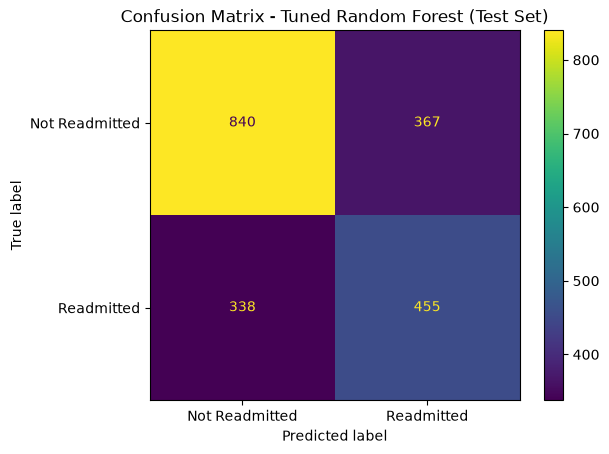

In [40]:
final_model = tuned_model
y_pred = final_model.predict(X_test)

print(classification_report(y_test, y_pred, target_names=["Not Readmitted", "Readmitted"]))

ConfusionMatrixDisplay.from_estimator(
    final_model, X_test, y_test,
    display_labels=["Not Readmitted", "Readmitted"],
)
plt.title("Confusion Matrix - Tuned Random Forest (Test Set)")
plt.show()

**How to read the confusion matrix:** rows are the actual outcome and columns are the model's prediction. The top-right cell holds false positives (flagged but not readmitted). The bottom-left cell holds false negatives (readmitted patients the model missed).

**Interpretation (original run, check against your output):** The tuned Random Forest correctly identifies about 57% of the readmitted patients (recall) and about 70% of those who were not readmitted. When it flags a patient, it is right about 55% of the time (precision). Test ROC-AUC is about 0.69, close to the cross-validated 0.689, which suggests the estimate is not inflated by overfitting. Performance is moderate overall: the model is better than guessing but far from reliable for individual patients.

## 10. Feature Importance

Random Forest feature importance shows which inputs the model relied on most. It describes *prediction*, not *cause*.

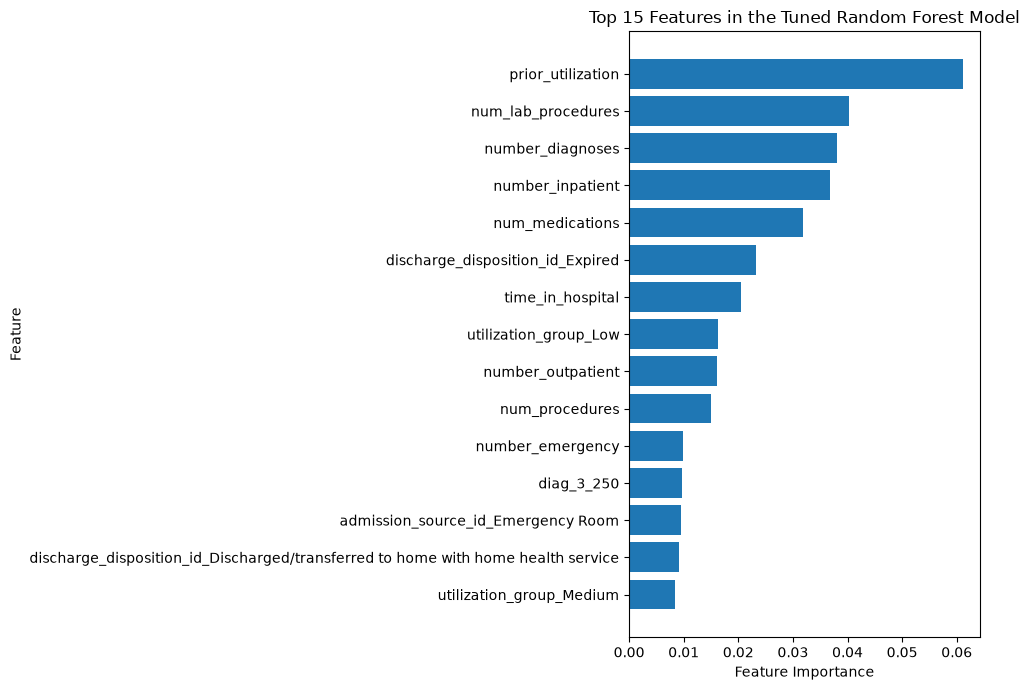

,Feature,Importance
8,prior_utilization,0.061200
1,num_lab_procedures,0.040351
7,number_diagnoses,0.038000
6,number_inpatient,0.036734
3,num_medications,0.031795
48,discharge_disposition_id_Expired,0.023294
0,time_in_hospital,0.020460
1449,utilization_group_Low,0.016277
4,number_outpatient,0.016116
2,num_procedures,0.015034


In [41]:
top_features = dm.get_feature_importance(final_model, top_n=15)

plt.figure(figsize=(10, 7))
plt.barh(top_features["Feature"][::-1], top_features["Importance"][::-1])
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 15 Features in the Tuned Random Forest Model")
plt.tight_layout()
plt.show()

top_features

**Interpretation (original run, check against your output):**
- The most used features were `prior_utilization`, `num_lab_procedures`, `number_diagnoses`, `number_inpatient`, and `num_medications`. This matches the EDA, where prior visits and diagnosis count showed clear differences between groups.
- The importance values are small and spread out (the top feature is only about 0.06). With one-hot encoding of diagnosis codes, the model has well over a thousand input columns, so importance gets divided among many features.
- Random Forest importance tends to favor numeric and high-cardinality features, so rankings should not be over-interpreted.
- `discharge_disposition_id = Expired` appears among the top features. Patients who die in hospital cannot be readmitted, so this reflects how the data is labeled, not a useful clinical pattern. The next section tests this.

## 11. Robustness Check: Removing Patients Who Died

Patients who died during the hospital stay cannot be readmitted, so keeping them mixes a non-clinical pattern into the model. First, look at the discharge categories to find every one that should be excluded (for example hospice categories, where patients are also unlikely to return).

In [42]:
df_clean["discharge_disposition_id"].value_counts(dropna=False)

discharge_disposition_id
Discharged to home                                                                                             6056
Discharged/transferred to SNF                                                                                  1190
Discharged/transferred to home with home health service                                                        1160
NaN                                                                                                             469
Expired                                                                                                         195
Discharged/transferred to another short term hospital                                                           185
Discharged/transferred to another rehab fac including rehab units of a hospital.                                171
Discharged/transferred to another  type of inpatient care institution                                           155
Not Mapped                                     

In [43]:
# Edit this list after looking at the table above (add hospice categories if present)
exclude = ["Expired"]

df_alt = dm.clean_data(df, exclude_values={"discharge_disposition_id": exclude})
X_train_alt, X_test_alt, y_train_alt, y_test_alt = dm.prepare_data(df_alt)

# Same tuned settings, retrained on the filtered data
best_params = {k.replace("classifier__", ""): v for k, v in grid.best_params_.items()}
alt_model = dm.train_model("random_forest", X_train_alt, y_train_alt, **best_params)

comparison = pd.concat([
    dm.evaluate_models({"Tuned RF (all encounters)": final_model}, X_test, y_test),
    dm.evaluate_models({"Tuned RF (deaths excluded)": alt_model}, X_test_alt, y_test_alt),
])
comparison

Removed 195 rows where discharge_disposition_id in ['Expired']
Dataset shape after cleaning: (9805, 48)
Dropping constant columns: ['acetohexamide', 'troglitazone', 'examide', 'citoglipton', 'glimepiride.pioglitazone', 'metformin.rosiglitazone', 'metformin.pioglitazone']
X_train: (7844, 40) | X_test: (1961, 40)


,Accuracy,Precision,Recall,F1 Score,ROC-AUC
Tuned RF (all encounters),0.648,0.554,0.574,0.563,0.688
Tuned RF (deaths excluded),0.646,0.564,0.549,0.556,0.681


**Interpretation (fill in after running):** Compare the two rows. The test sets are slightly different (the second one has the excluded patients removed), so the comparison is approximate. Did performance change? Did `Expired` disappear from the feature importance list? Write what you found and which version you consider more appropriate for the final model: ______________________

## 12. Conclusion

**Best model:** The tuned Random Forest was selected because it had the highest cross-validated ROC-AUC. On the held-out test set it reached an accuracy of about 65%, precision of about 55%, recall of about 57%, F1-score of about 56%, and ROC-AUC of about 0.69. *(Update these numbers from your final run.)*

**What the results mean:** The model identifies somewhat more than half of the patients who are later readmitted, but it also flags many patients who are not (precision is only about 55%). It ranks patients by risk better than chance, but not well enough to make decisions about individual patients on its own. Prior healthcare use, number of diagnoses, and medication count were among the features the model relied on most, in line with the EDA.

**Effect of tuning and class balancing:** Tuning improved cross-validated ROC-AUC only slightly (about 0.681 to 0.689). The large recall gain came mostly from class weighting, which trades precision for recall rather than improving overall ranking.

### Limitations
- Performance is moderate: ROC-AUC is below 0.70, and the model should not be used for clinical decisions without further validation.
- Feature importance shows predictive contribution, not causation.
- The dataset has 10,000 encounters, which limits how much complexity the models can learn. Results come from a single train/test split.
- Diagnosis codes are one-hot encoded, creating over a thousand sparse columns. Grouping the codes into broader categories could help.
- Encounters that end in death (and possibly hospice) cannot lead to readmission (see Section 11).
- If multiple encounters belong to the same patient, they may appear in both training and test sets. The dataset has no patient identifier, so this could not be checked.
- Missing `A1Cresult` and `max_glu_serum` values were dropped, though "not measured" may carry information.

### Possible Next Steps
- Keep or drop the final handling of deaths and hospice based on the Section 11 results.
- Group diagnosis codes into broader clinical categories to reduce the number of features.
- Add a "not measured" category for A1C and glucose results and test whether it helps.
- Choose the decision cutoff based on the cost of missing a readmission versus flagging too many patients, instead of using 0.5.
- Try gradient boosting once the validation and preprocessing steps are settled.